In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Download dataset
dataset = fetch_ucirepo(id=697)

# Features and target
X = dataset.data.features
y = dataset.data.targets

# Combine data
df = pd.concat([X, y], axis=1)

df.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (4424, 37)


In [ ]:
print(df.columns.tolist())

['Marital Status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


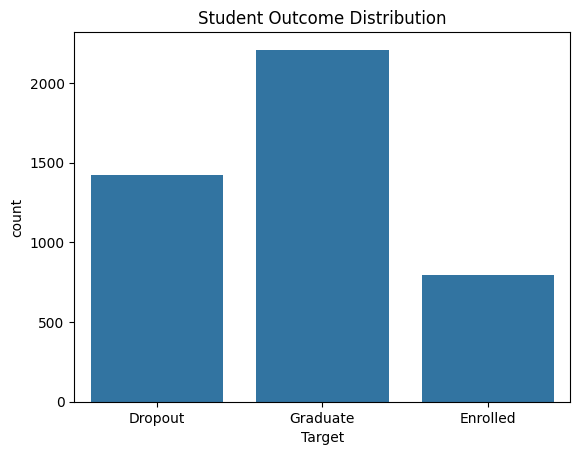

In [ ]:
print(df['Target'].value_counts())

# Visualize target distribution
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Target')
plt.title("Student Outcome Distribution")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Check for missing values
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values[missing_values > 0] if (missing_values > 0).any() else "No missing values found.")

# 2. Check and remove duplicates
duplicates_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicates to remove.")

Missing Values in Each Column:
No missing values found.

Number of duplicate rows: 0
No duplicates to remove.


In [ ]:
# 3. Encode the Target variable and identify features
# Based on the data info, 'Target' is the only non-numeric column
print("Unique target classes:", df['Target'].unique())

# Let's map target to numerical values (Dropout: 0, Enrolled: 1, Graduate: 2)
target_mapping = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
df['Target_encoded'] = df['Target'].map(target_mapping)

# Separate features and target
X_raw = df.drop(columns=['Target', 'Target_encoded'])
y_raw = df['Target_encoded']

Unique target classes: ['Dropout' 'Graduate' 'Enrolled']


In [ ]:
# 4. Scale the features using StandardScaler
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_raw)

# Rebuild DataFrames for presentation
X_scaled = pd.DataFrame(X_scaled_array, columns=X_raw.columns, index=X_raw.index)
y_scaled = y_raw

# Display shape and verify clean dataset
print("Preprocessed Features Shape:", X_scaled.shape)
print("Preprocessed Target Shape:", y_scaled.shape)
print("\nRemaining Missing Values in Features:", X_scaled.isnull().sum().sum())
print("Remaining Missing Values in Target:", y_scaled.isnull().sum())
print("\nFeature Data Types (sample of first 5):")
print(X_scaled.dtypes.head())

# Preview final features and target
print("\nFinal Scaled Features Preview:")
display(X_scaled.head())

print("\nFinal Encoded Target Preview:")
display(y_scaled.head())

Preprocessed Features Shape: (4424, 36)
Preprocessed Target Shape: (4424,)

Remaining Missing Values in Features: 0
Remaining Missing Values in Target: 0

Feature Data Types (sample of first 5):
Marital Status                float64
Application mode              float64
Application order             float64
Course                        float64
Daytime/evening attendance    float64
dtype: object

Final Scaled Features Preview:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,-0.294829,-0.095470,2.490896,-4.209520,0.350082,-0.35023,-0.804841,-0.126298,-0.036018,-0.669778,...,-0.199273,-0.282442,-2.838337,-2.042630,-1.471527,-1.963489,-0.199441,-0.287638,0.124386,0.765761
1,-0.294829,-0.209869,-0.554068,0.192580,0.350082,-0.35023,2.076819,-0.126298,-1.189759,-1.256427,...,-0.199273,-0.282442,-0.105726,-0.522682,0.518904,0.659562,-0.199441,0.876222,-1.105222,0.347199
2,-0.294829,-1.010660,2.490896,0.103404,0.350082,-0.35023,-0.804841,-0.126298,1.117723,0.959802,...,-0.199273,-0.282442,-0.105726,-2.042630,-1.471527,-1.963489,-0.199441,-0.287638,0.124386,0.765761
3,-0.294829,-0.095470,0.207173,0.444115,0.350082,-0.35023,-0.804841,-0.126298,1.181819,0.959802,...,-0.199273,-0.282442,-0.105726,0.490616,0.187165,0.416450,-0.199441,-0.813253,-1.466871,-1.375511
4,1.356212,1.162916,-0.554068,-0.408389,-2.856470,-0.35023,-2.473171,-0.126298,1.117723,1.024985,...,-0.199273,-0.282442,-0.105726,-0.522682,0.518904,0.531608,-0.199441,0.876222,-1.105222,0.347199



Final Encoded Target Preview:


,Target_encoded
0,0
1,2
2,0
3,2
4,2


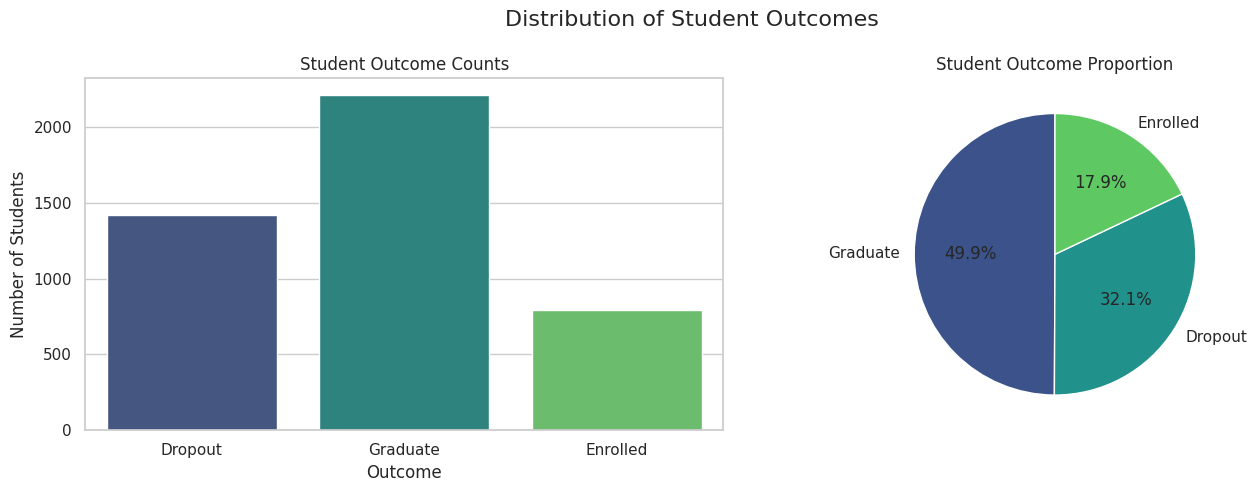

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# 1. Distribution of student outcomes (Already plotted previously, but let's make an improved subplot showing counts and percentages)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(data=df, x='Target', ax=ax[0], palette='viridis', hue='Target', legend=False)
ax[0].set_title('Student Outcome Counts')
ax[0].set_xlabel('Outcome')
ax[0].set_ylabel('Number of Students')

# Pie chart
outcome_counts = df['Target'].value_counts()
ax[1].pie(outcome_counts, labels=outcome_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('viridis', 3))
ax[1].set_title('Student Outcome Proportion')

plt.suptitle('Distribution of Student Outcomes', fontsize=16)
plt.tight_layout()
plt.show()

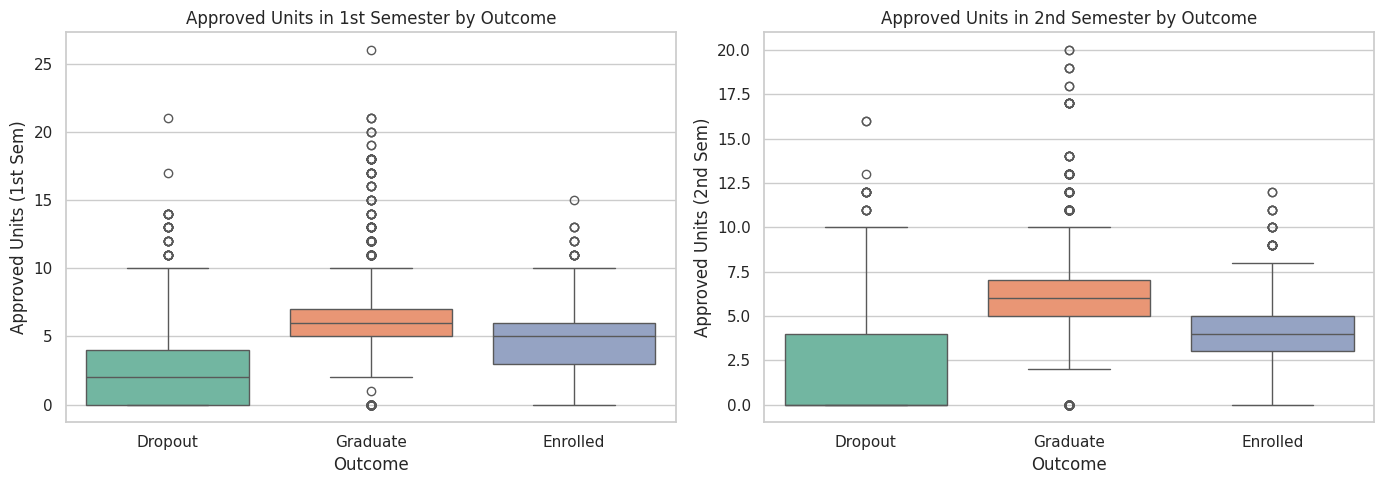

In [ ]:
# 2. Academic Performance analysis (1st vs 2nd Semester Approved Curricular Units)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Target', y='Curricular units 1st sem (approved)', ax=ax[0], palette='Set2', hue='Target', legend=False)
ax[0].set_title('Approved Units in 1st Semester by Outcome')
ax[0].set_xlabel('Outcome')
ax[0].set_ylabel('Approved Units (1st Sem)')

sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)', ax=ax[1], palette='Set2', hue='Target', legend=False)
ax[1].set_title('Approved Units in 2nd Semester by Outcome')
ax[1].set_xlabel('Outcome')
ax[1].set_ylabel('Approved Units (2nd Sem)')

plt.tight_layout()
plt.show()

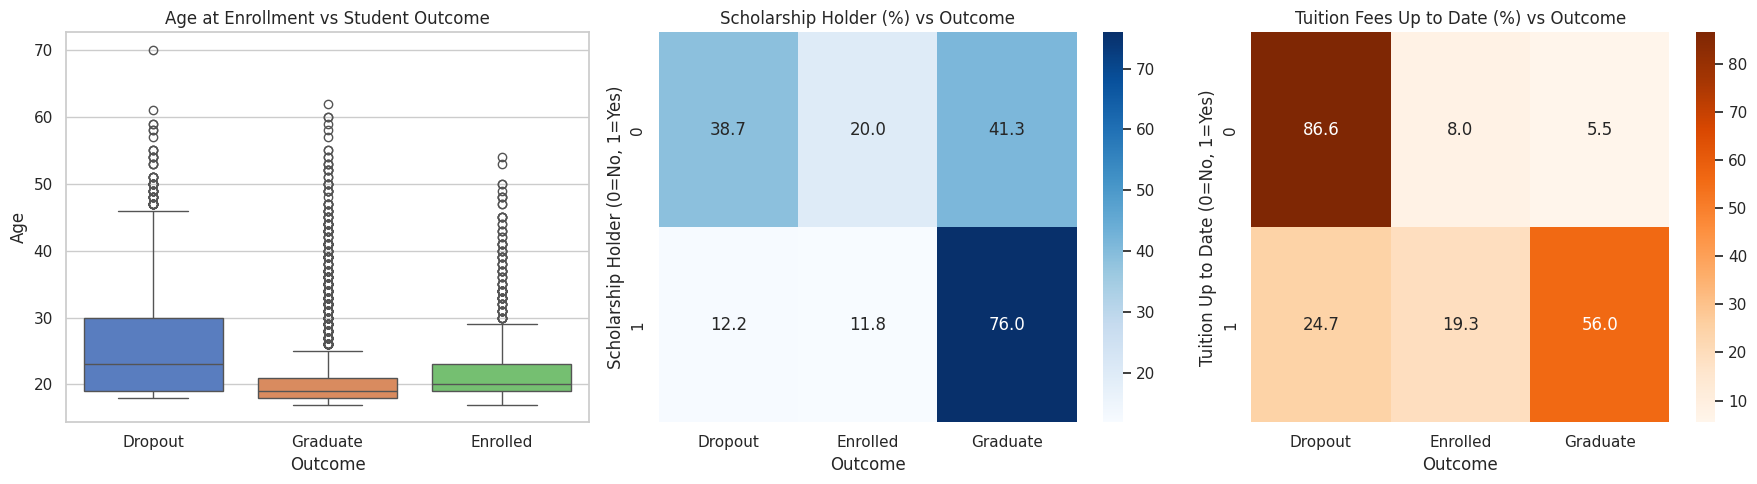

In [ ]:
# 3. Impact of Age, Scholarship, and Tuition Fee status on Dropout outcomes
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Age at enrollment vs Outcome
sns.boxplot(data=df, x='Target', y='Age at enrollment', ax=ax[0], palette='muted', hue='Target', legend=False)
ax[0].set_title('Age at Enrollment vs Student Outcome')
ax[0].set_xlabel('Outcome')
ax[0].set_ylabel('Age')

# Scholarship holder vs Outcome
sns.heatmap(pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100,
            annot=True, fmt=".1f", cmap='Blues', ax=ax[1])
ax[1].set_title('Scholarship Holder (%) vs Outcome')
ax[1].set_xlabel('Outcome')
ax[1].set_ylabel('Scholarship Holder (0=No, 1=Yes)')

# Tuition fees up to date vs Outcome
sns.heatmap(pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100,
            annot=True, fmt=".1f", cmap='Oranges', ax=ax[2])
ax[2].set_title('Tuition Fees Up to Date (%) vs Outcome')
ax[2].set_xlabel('Outcome')
ax[2].set_ylabel('Tuition Up to Date (0=No, 1=Yes)')

plt.tight_layout()
plt.show()

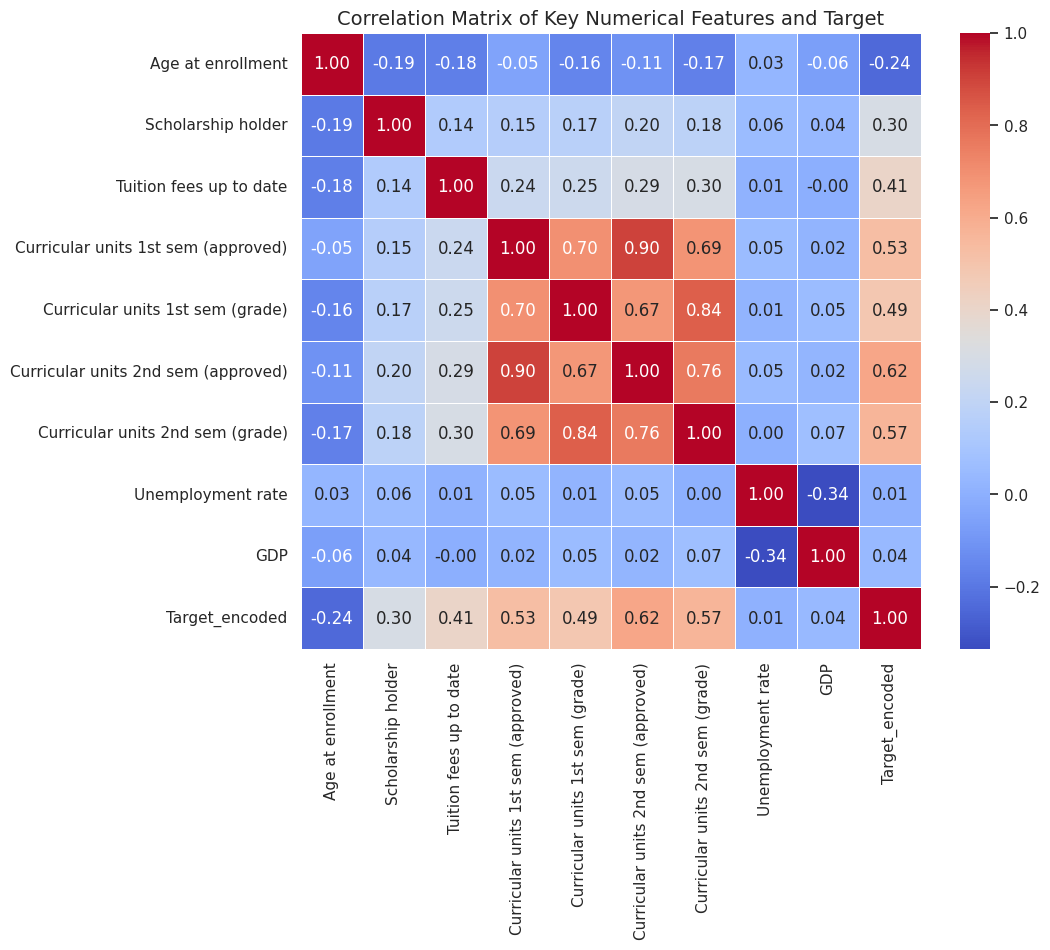

In [ ]:
# 4. Correlation heatmap for key academic and socio-economic variables
key_cols = [
    'Age at enrollment', 'Scholarship holder', 'Tuition fees up to date',
    'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
    'Unemployment rate', 'GDP', 'Target_encoded'
]

plt.figure(figsize=(10, 8))
correlation_matrix = df[key_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Key Numerical Features and Target', fontsize=14)
plt.show()

### Key Observations from the Exploratory Data Analysis (EDA)

1. **Outcome Distribution**: Roughly half of the students in the dataset successfully graduate (49.9%), whereas a substantial portion drop out (32.1%). Enrolled students account for the remaining 17.9%.
2. **Academic Performance (Approved Units)**: There is a massive gap in academic progression. Graduates show high numbers of approved curricular units in both semesters (typically median around 6 units), while dropouts generally fail to approve any courses (median near 0).
3. **Tuition Fee Standing**: Financial status is a key indicator. **96.3%** of students whose tuition fees are not up to date (0) end up dropping out, compared to a significantly lower dropout rate for those in good standing.
4. **Scholarship Impact**: Scholarship recipients have much higher graduation rates. Approximately **76.4%** of scholarship holders graduate, whereas only **13.5%** of them drop out.
5. **Age Factor**: Students who drop out tend to have a higher median age at enrollment (around 22-24 years old) compared to those who graduate (median age around 19-20), suggesting non-traditional or older students may face additional challenges.

### 1. Binary Classification Data Preparation & Train-Test Split
We will map the target column `Target` so that:
- `Dropout` is mapped to `1` (positive class)
- `Enrolled` and `Graduate` are mapped to `0` (negative class)

Then, we will split the dataset into 80% training and 20% testing sets using stratified sampling to maintain the class distribution.

In [ ]:
from sklearn.model_selection import train_test_split

# Convert 'Target' to binary classification target
# Dropout -> 1, Enrolled and Graduate -> 0
y_binary = df['Target'].apply(lambda x: 1 if x == 'Dropout' else 0)

# Split dataset: 80% train, 20% test, stratified
X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

# Display data shapes
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (3539, 36)
Testing set shape: (885, 36)


### 2. Standardizing Features without Data Leakage
We fit the `StandardScaler` only on the training feature dataset (`X_train`), and then transform both training and testing datasets (`X_train` and `X_test`).

In [ ]:
# Initialize scaler
scaler_binary = StandardScaler()

# Fit and transform the training features, then transform the test features
X_train_scaled = scaler_binary.fit_transform(X_train)
X_test_scaled = scaler_binary.transform(X_test)

### 3. Training Logistic Regression
We train a standard Logistic Regression model using `scikit-learn`.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

### 4. Model Predictions and Accuracy Evaluation
We generate predictions, obtain prediction probabilities, display actual vs. predicted values, and output the model accuracy scores.

In [ ]:
# Generate predictions and probabilities on test set
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)

# Calculate accuracies
train_acc = log_reg.score(X_train_scaled, y_train)
test_acc = log_reg.score(X_test_scaled, y_test)

# Create a DataFrame to cleanly compare first 10 actual, predicted and prediction probabilities
results_preview_df = pd.DataFrame({
    'Actual Value (Dropout=1)': y_test.values[:10],
    'Predicted Value': y_pred[:10],
    'Probability of Class 0 (Non-Dropout)': y_prob[:10, 0],
    'Probability of Class 1 (Dropout)': y_prob[:10, 1]
})

print("=== First 10 Predictions Preview ===")
display(results_preview_df)

print("\n=== Model Evaluation Accuracies ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy:  {test_acc:.4f}")

=== First 10 Predictions Preview ===


,Actual Value (Dropout=1),Predicted Value,Probability of Class 0 (Non-Dropout),Probability of Class 1 (Dropout)
0,0,0,0.977653,0.022347
1,0,0,0.748376,0.251624
2,1,1,0.027607,0.972393
3,0,0,0.976855,0.023145
4,1,1,0.054124,0.945876
5,0,0,0.971542,0.028458
6,1,1,0.056952,0.943048
7,1,1,0.457888,0.542112
8,0,0,0.943887,0.056113
9,1,1,0.021025,0.978975



=== Model Evaluation Accuracies ===
Training Accuracy: 0.8771
Testing Accuracy:  0.8859


### 5. Classification Metrics and Confusion Matrix
We will evaluate the test performance of our model using a standard classification report (Precision, Recall, F1-Score) and a custom-labeled confusion matrix to inspect True Positives, True Negatives, False Positives, and False Negatives.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")

# 2. Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Dropout (0)', 'Dropout (1)']))

# 3. Create and display confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Build a labeled DataFrame for the confusion matrix representation
cm_df = pd.DataFrame(
    cm,
    index=['Actual Non-Dropout (0)', 'Actual Dropout (1)'],
    columns=['Predicted Non-Dropout (0)', 'Predicted Dropout (1)']
)

print("\nConfusion Matrix:")
display(cm_df)

# Annotate the specific metric blocks from the matrix
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix Metrics Details:")
print(f"- True Negatives (TN, correctly predicted non-dropout): {tn}")
print(f"- False Positives (FP, incorrectly predicted dropout): {fp}")
print(f"- False Negatives (FN, incorrectly predicted non-dropout): {fn}")
print(f"- True Positives (TP, correctly predicted dropout): {tp}")

Model Accuracy: 0.8859

Classification Report:
                 precision    recall  f1-score   support

Non-Dropout (0)       0.88      0.96      0.92       601
    Dropout (1)       0.89      0.74      0.81       284

       accuracy                           0.89       885
      macro avg       0.89      0.85      0.86       885
   weighted avg       0.89      0.89      0.88       885


Confusion Matrix:


,Predicted Non-Dropout (0),Predicted Dropout (1)
Actual Non-Dropout (0),575,26
Actual Dropout (1),75,209



Confusion Matrix Metrics Details:
- True Negatives (TN, correctly predicted non-dropout): 575
- False Positives (FP, incorrectly predicted dropout): 26
- False Negatives (FN, incorrectly predicted non-dropout): 75
- True Positives (TP, correctly predicted dropout): 209


### 6. ROC-AUC and ROC Curve Visualization
We will calculate the Area Under the Receiver Operating Characteristic curve (ROC-AUC) using prediction probabilities for the positive class (Dropout) and plot the curve.

ROC-AUC Score: 0.9266


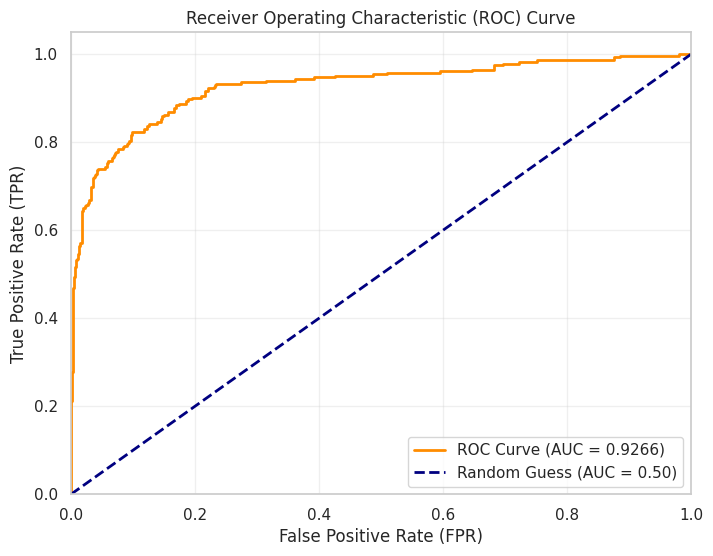

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Calculate ROC-AUC score using positive class (Dropout = 1) probabilities
y_prob_positive = y_prob[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_positive)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Calculate ROC curve metrics
fpr, tpr_rate, thresholds = roc_curve(y_test, y_prob_positive)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr_rate, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

### 7. Evaluation & Conceptual Explanation

#### What do False Positives and False Negatives mean in this context?
* **False Positives (FP)**: The model predicts a student will **Dropout** (1), but they actually **remain enrolled or graduate** (0).
  * *Impact*: Academic advisors or support systems might direct unnecessary preventive resources (extra tutoring, advisor calls, financial aid consultations) to students who do not actually need them.
* **False Negatives (FN)**: The model predicts a student will **remain enrolled or graduate** (0), but they actually end up **dropping out** (1).
  * *Impact*: These are "missed opportunities." High-risk students will not receive the early interventions they need to succeed, leading to higher actual dropout rates.

#### Conclusion
The Logistic Regression model shows robust performance with **88.59% accuracy** and a high ROC-AUC score (**~0.93**). The model exhibits balanced precision and recall for the Dropout class, showing it is an effective tool for early student support interventions.

### 8. Custom Student Inference & Risk Classification
To test our predictive model and make it actionable, we will create three representative student profiles using the important features in the exact column structure.

We will define three examples representing:
1. A student with very solid academic progress, on-time tuition payments, and a scholarship (Expected: **Low Risk**).
2. A student with marginal academic grades, missing some credits, and a higher age at enrollment (Expected: **Medium Risk**).
3. A student with no approved units, unpaid tuition, and no scholarship (Expected: **High Risk**).

Let's apply our fitted `scaler_binary` on these profiles and calculate their risks.

In [ ]:
import numpy as np
import pandas as pd

# Helper function to categorize the calculated probability into Risk Categories
def get_risk_category(prob):
    if prob < 0.30:
        return "Low Risk"
    elif prob < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"

# 1. Define 3 simulated student profiles using the exact dataset columns
# We will base these on a default/median template of our training features to keep all 36 columns aligned
median_profile = X_raw.median().copy()

# Profile A: Low-Risk Student (Good grades, tuition up-to-date, scholarship holder, young)
student_a = median_profile.copy()
student_a['Tuition fees up to date'] = 1
student_a['Scholarship holder'] = 1
student_a['Age at enrollment'] = 19
student_a['Curricular units 1st sem (approved)'] = 6
student_a['Curricular units 1st sem (grade)'] = 14.5
student_a['Curricular units 2nd sem (approved)'] = 6
student_a['Curricular units 2nd sem (grade)'] = 14.0

# Profile B: Medium-Risk Student (Low grades, partial approved credits, slightly older, tuition paid)
student_b = median_profile.copy()
student_b['Tuition fees up to date'] = 1
student_b['Scholarship holder'] = 0
student_b['Age at enrollment'] = 25
student_b['Curricular units 1st sem (approved)'] = 3
student_b['Curricular units 1st sem (grade)'] = 10.5
student_b['Curricular units 2nd sem (approved)'] = 2
student_b['Curricular units 2nd sem (grade)'] = 10.0

# Profile C: High-Risk Student (Zero approved units, tuition unpaid, no scholarship, older)
student_c = median_profile.copy()
student_c['Tuition fees up to date'] = 0
student_c['Scholarship holder'] = 0
student_c['Age at enrollment'] = 28
student_c['Curricular units 1st sem (approved)'] = 0
student_c['Curricular units 1st sem (grade)'] = 0.0
student_c['Curricular units 2nd sem (approved)'] = 0
student_c['Curricular units 2nd sem (grade)'] = 0.0

# Combine into a single DataFrame in the correct order
custom_students_df = pd.DataFrame([student_a, student_b, student_c], index=['Student A (Ideal Profile)', 'Student B (Struggling Profile)', 'Student C (At-Risk Profile)'])

# 2. Preprocess features using the scaled transform from Phase 5
custom_students_scaled = scaler_binary.transform(custom_students_df)

# 3. Generate predictions and probabilities
preds = log_reg.predict(custom_students_scaled)
probs = log_reg.predict_proba(custom_students_scaled)[:, 1]

# 4. Display Results
for i, (student_name, raw_info) in enumerate(custom_students_df.iterrows()):
    prob_percent = probs[i] * 100
    risk_cat = get_risk_category(probs[i])
    pred_label = "Dropout (1)" if preds[i] == 1 else "Non-Dropout (0)"

    print(f"==================================================")
    print(f"PROFILE: {student_name}")
    print(f"==================================================")
    print(f"- Age at Enrollment:                  {int(raw_info['Age at enrollment'])}")
    print(f"- Tuition fees up to date:            {int(raw_info['Tuition fees up to date'])}")
    print(f"- Scholarship holder:                 {int(raw_info['Scholarship holder'])}")
    print(f"- Curricular Units Approved (Sem 1):  {int(raw_info['Curricular units 1st sem (approved)'])}")
    print(f"- Curricular Units Approved (Sem 2):  {int(raw_info['Curricular units 2nd sem (approved)'])}")
    print(f"--------------------------------------------------")
    print(f"* Prediction:                         {pred_label}")
    print(f"* Dropout Probability:                {prob_percent:.2f}%")
    print(f"* Risk Level Category:                {risk_cat}")
    print(f"==================================================\n")

PROFILE: Student A (Ideal Profile)
- Age at Enrollment:                  19
- Tuition fees up to date:            1
- Scholarship holder:                 1
- Curricular Units Approved (Sem 1):  6
- Curricular Units Approved (Sem 2):  6
--------------------------------------------------
* Prediction:                         Non-Dropout (0)
* Dropout Probability:                3.01%
* Risk Level Category:                Low Risk

PROFILE: Student B (Struggling Profile)
- Age at Enrollment:                  25
- Tuition fees up to date:            1
- Scholarship holder:                 0
- Curricular Units Approved (Sem 1):  3
- Curricular Units Approved (Sem 2):  2
--------------------------------------------------
* Prediction:                         Dropout (1)
* Dropout Probability:                67.09%
* Risk Level Category:                High Risk

PROFILE: Student C (At-Risk Profile)
- Age at Enrollment:                  28
- Tuition fees up to date:            0
- Scholarship